Clustering

In [28]:
import re, os, sqlite3, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.feature_extraction.text import TfidfVectorizer, ENGLISH_STOP_WORDS
from sklearn.decomposition import TruncatedSVD
from sklearn.cluster import KMeans
from sklearn.manifold import TSNE
from sklearn.metrics import (silhouette_score, adjusted_rand_score, accuracy_score,
                             f1_score, classification_report, confusion_matrix)
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.preprocessing import Normalizer


In [29]:
warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
RANDOM_STATE = 42
DATA_PATH = "/content/faculty_eda_done.csv"
DB_PATH   = "/content/iisermohali_faculty.db"

In [30]:
df = pd.read_csv(DATA_PATH)

Research Interests

In [31]:
df["ri_len_raw"] = df["Research Interests"].fillna("").str.len()
print(df["ri_len_raw"].describe().round(0))

example = df.loc[df["ri_len_raw"].idxmax()]
print("\nLongest entry:", example["Name"], example["ri_len_raw"], "characters")
print(example["Research Interests"][:400], "...")

count       135.0
mean      58770.0
std       90780.0
min           0.0
25%       20430.0
50%       43265.0
75%       62927.0
max      785206.0
Name: ri_len_raw, dtype: float64

Longest entry: Angshuman Roy Choudhury 785206 characters
Our group focuses on the crystallographic askects of various organic, organometallic and MOF materials. We work on experimental and theoretical charge density analysis, synthesis, characterization and applications of MOFs, supramolecular chemistry, crystal engineering etc. 2007 - 2009 : Assistant Professor, Birla Institute of Technology and Science, Pilani 2004 - 2007 : Post doctoral Research Asso ...


Removing unnecessary blurb

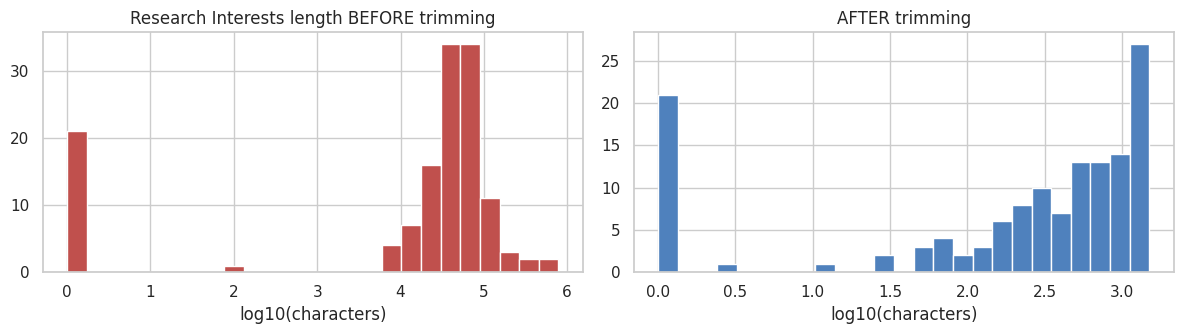

median chars before: 43265 | after: 459


In [32]:

CUT = re.compile(
    r"(?:Since\s+(?:[A-Z][a-z]{2}\s+)?\d{4}|\b(?:19|20)\d{2}\s*(?:[-\u2013]\s*(?:(?:19|20)\d{2}|[Pp]resent))?)\s*:"   # '2004 - 2009 :' or 'Since 2015 :'
    r"|\bPh\.?\s?D\.?\s*[,(]"                      # 'Ph.D.,' 'PhD ('
    r"|\b[BM]\.?\s?(?:Sc|Tech)\b"                   # 'M.Sc' 'B.Tech'
    r"|\bPublications?\b|\bURL\s*,|\bDOI\b"          # publication lists
    r"|\(\s*(?:19|20)\d{2}\s*\)"                    # '(2019)'
    r"|\b\d{1,4}\s*\(\d{1,3}\)\s*:\s*\d+"            # '47(41):18995'
    r"|\b(?:19|20)\d{2}\s*[;.,]\s*\d+"              # '2023. 45'
)
MAX_CHARS = 1500

def trim_interests(text, name=""):
    if not isinstance(text, str):
        return ""
    m = CUT.search(text)
    if m:
        text = text[:m.start()]

    surname = name.replace("Prof.", "").replace("Dr.", "").split()[-1] if name.strip() else ""
    if len(surname) >= 4:
        k = text.find(surname)
        if k > 0:
            text = text[:k]
    return text[:MAX_CHARS].strip()

df["Interests_trimmed"] = [trim_interests(t, n) for t, n in zip(df["Research Interests"], df["Name"])]
df["ri_len_trim"] = df["Interests_trimmed"].str.len()

fig, ax = plt.subplots(1, 2, figsize=(12, 3.5))
ax[0].hist(np.log10(df["ri_len_raw"].clip(lower=1)), bins=25, color="#c0504d")
ax[0].set_title("Research Interests length BEFORE trimming"); ax[0].set_xlabel("log10(characters)")
ax[1].hist(np.log10(df["ri_len_trim"].clip(lower=1)), bins=25, color="#4f81bd")
ax[1].set_title("AFTER trimming"); ax[1].set_xlabel("log10(characters)")
plt.tight_layout(); plt.show()

print("median chars before:", int(df["ri_len_raw"].median()), "| after:", int(df["ri_len_trim"].median()))

Research text cleaning



In [33]:
DOMAIN_STOP = set('''
research researcher researchers study studies studied work works working worked interest interests interested
group groups lab laboratory currently current use used using based including include includes various different
related area areas approach approaches also new problem problems particular particularly focus focuses focused
understand understanding develop developed developing development role aspects aspect broad range topics topic
field fields many well within towards toward employ employing apply applications application recent major
iiser mohali professor assistant associate dr prof phd student students theory
'''.split())
STOP = set(ENGLISH_STOP_WORDS) | DOMAIN_STOP

def clean_text(text):
    text = str(text).lower()
    text = re.sub(r"https?://\S+|www\.\S+|\S+@\S+", " ", text)
    text = re.sub(r"[^a-z\s]", " ", text)
    toks = [t for t in text.split() if len(t) >= 3 and t not in STOP]
    return " ".join(toks)

df["Research Text"] = (df["Research Area"].fillna("") + " ") * 2 + df["Interests_trimmed"]
df["Text Clean"]    = df["Research Text"].apply(clean_text)
df["n_tokens"]      = df["Text Clean"].str.split().str.len()

df["is_regular"] = df["Category"].eq("Regular Faculty")
df["has_text"]   = df["n_tokens"] >= 3          # need at least a few informative words

print(pd.crosstab(df["is_regular"], df["has_text"], rownames=["regular faculty"], colnames=["usable text"]))
model_df = df[df["is_regular"] & df["has_text"]].reset_index(drop=True)
print("\nFaculty used for modelling:", len(model_df))
print(model_df["Department"].value_counts().to_string())

usable text      False  True 
regular faculty              
False                9      4
True                12    110

Faculty used for modelling: 110
Department
DCS    24
DBS    24
DPS    23
DMS    19
EES    12
HSS     8


In [34]:
print("Tokens per profile:")
print(model_df["n_tokens"].describe().round(1))
model_df[["Name", "Department", "Text Clean"]].head(5)

Tokens per profile:
count    110.0
mean      61.5
std       39.2
min        4.0
25%       27.0
50%       57.0
75%       97.5
max      146.0
Name: n_tokens, dtype: float64


,Name,Department,Text Clean
0,Abhik Ganguli,DMS,number number number galois representations mo...
1,Abhishek Chaudhuri,DPS,condensed matter physics soft biological matte...
2,Adrene Freeda Dcruz,HSS,science theatre media trauma scatology science...
3,Ambresh Shivaji,DPS,theoretical high energy physics theoretical hi...
4,Amar Deep,DBS,molecular structural biology molecular structu...


 TF-IDF

In [35]:
tfidf = TfidfVectorizer(ngram_range=(1, 2), min_df=2, max_df=0.5, sublinear_tf=True)
X = tfidf.fit_transform(model_df["Text Clean"])
terms = np.array(tfidf.get_feature_names_out())
print("TF-IDF matrix:", X.shape, "| sparsity:", round(1 - X.nnz / np.prod(X.shape), 3))

TF-IDF matrix: (110, 1041) | sparsity: 0.97


In [36]:
# Keyword extraction: the top TF-IDF terms for every person
def top_terms_for_row(i, k=6):
    row = X[i].toarray().ravel()
    idx = row.argsort()[::-1][:k]
    return ", ".join(terms[idx][row[idx] > 0])

model_df["Keywords"] = [top_terms_for_row(i) for i in range(X.shape[0])]
model_df[["Name", "Department", "Keywords"]].head(12)

,Name,Department,Keywords
0,Abhik Ganguli,DMS,"representations, number, galois representation..."
1,Abhishek Chaudhuri,DPS,"equilibrium, soft, condensed matter, condensed..."
2,Adrene Freeda Dcruz,HSS,"science, addresses, charles, literary, apart, ..."
3,Ambresh Shivaji,DPS,"energy physics, high energy, physics, energy, ..."
4,Amar Deep,DBS,"bacterial, immune, structural biology, innate,..."
5,Amit Kulshrestha,DMS,"central simple, simple algebras, algebras, map..."
6,Angshuman Roy Choudhury,DCS,"crystal, engineering, solid state, solid, stat..."
7,Anil Kumar Dasanna,DPS,"soft, matter, soft biological, soft matter, bi..."
8,Anil Kumar Tripathi,DBS,"promoting, genetics genomics, synthetic biolog..."
9,Anoop Ambili,EES,"geochemistry, environmental, systems, ecosyste..."


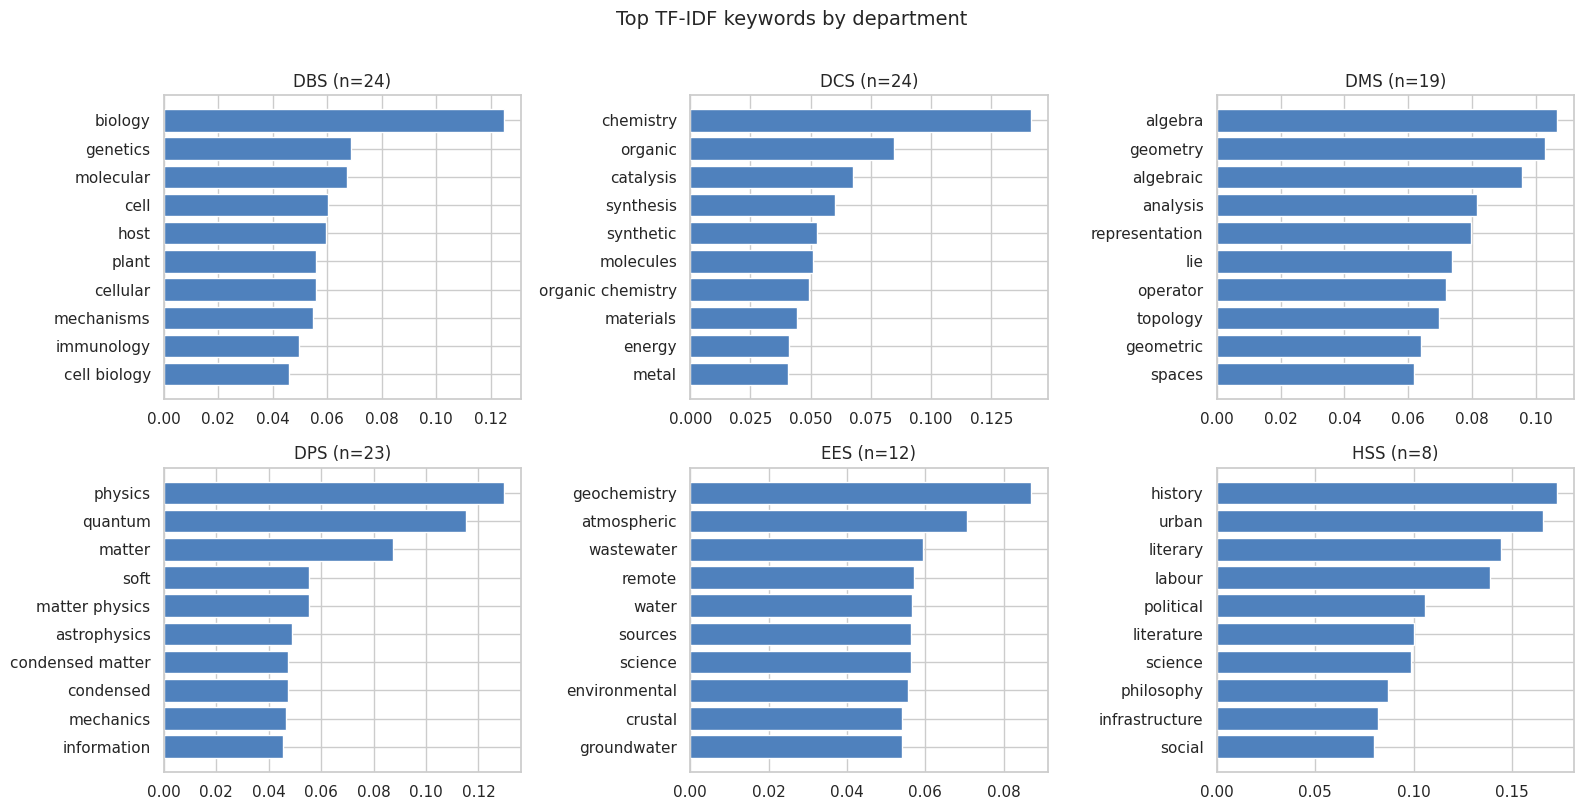

In [37]:
depts = sorted(model_df["Department"].unique())
fig, axes = plt.subplots(2, 3, figsize=(16, 8))
for ax, dep in zip(axes.ravel(), depts):
    mask = (model_df["Department"] == dep).values
    mean_w = np.asarray(X[mask].mean(axis=0)).ravel()
    idx = mean_w.argsort()[::-1][:10]
    ax.barh(terms[idx][::-1], mean_w[idx][::-1], color="#4f81bd")
    ax.set_title(f"{dep} (n={mask.sum()})")
for ax in axes.ravel()[len(depts):]:
    ax.axis("off")
plt.suptitle("Top TF-IDF keywords by department", y=1.01, fontsize=14)
plt.tight_layout(); plt.show()

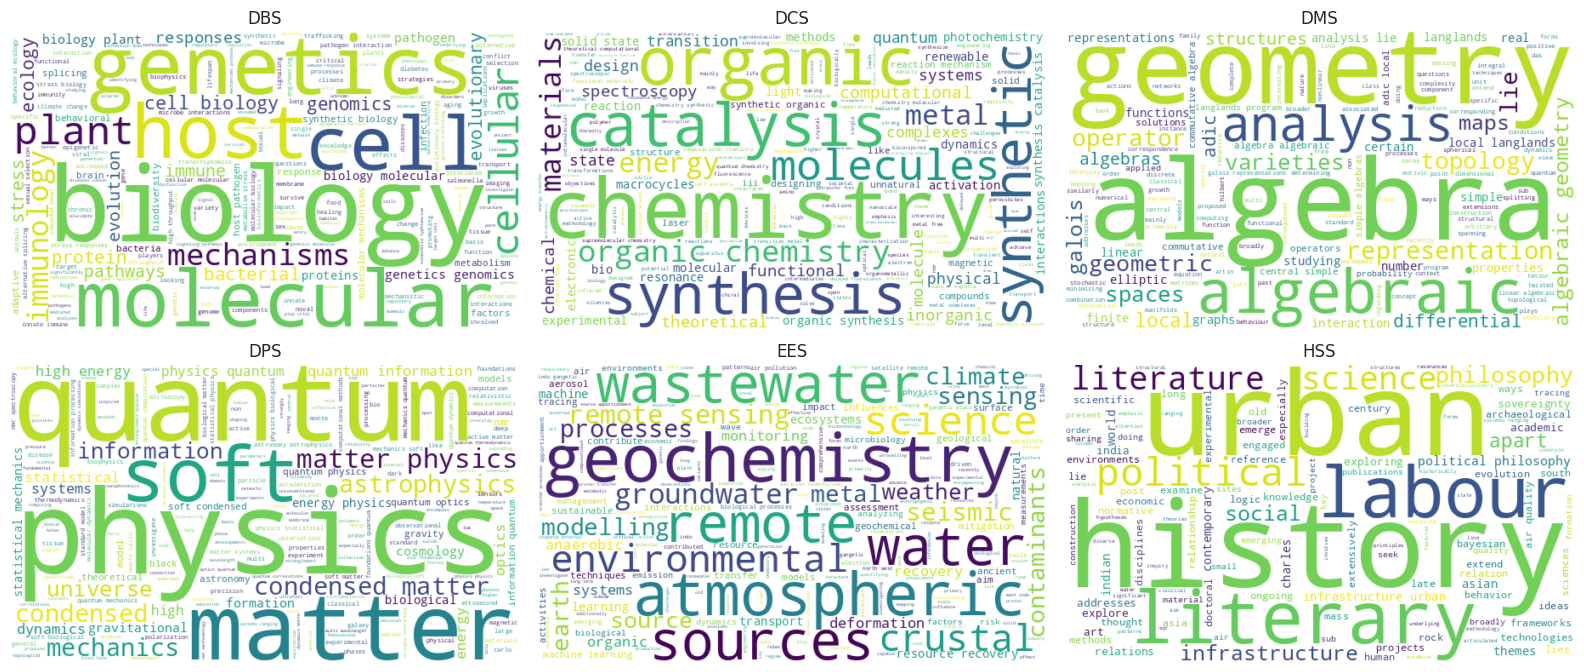

In [27]:

    from wordcloud import WordCloud
    fig, axes = plt.subplots(2, 3, figsize=(16, 7))
    for ax, dep in zip(axes.ravel(), depts):
        mask = (model_df["Department"] == dep).values
        w = np.asarray(X[mask].mean(axis=0)).ravel()
        freq = {t: v for t, v in zip(terms, w) if v > 0}
        wc = WordCloud(width=600, height=350, background_color="white", random_state=1).generate_from_frequencies(freq)
        ax.imshow(wc, interpolation="bilinear"); ax.axis("off"); ax.set_title(dep)
    for ax in axes.ravel()[len(depts):]:
        ax.axis("off")
    plt.tight_layout()
    plt.show()


 Clustering research areas

20 SVD components keep 34.1% of the variance


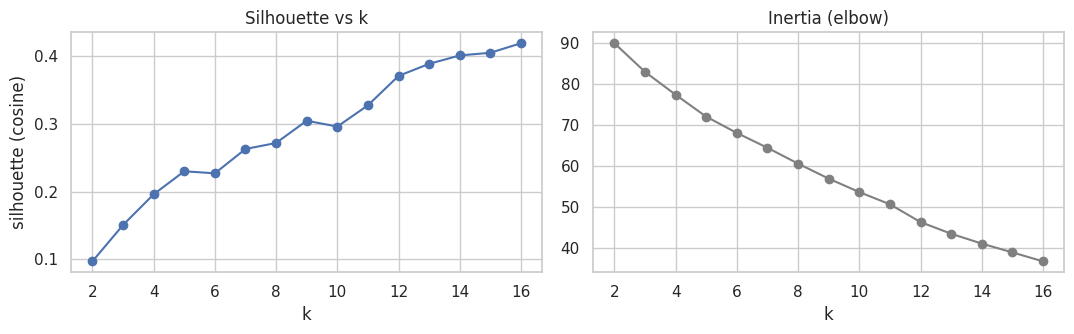

,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14
k,2.000,3.000,4.000,5.00,6.000,7.000,8.000,9.000,10.000,11.000,12.000,13.000,14.000,15.000,16.000
silhouette,0.097,0.151,0.196,0.23,0.227,0.263,0.272,0.305,0.296,0.327,0.371,0.388,0.401,0.405,0.419


In [38]:
N_COMP = 20
svd = TruncatedSVD(n_components=N_COMP, random_state=RANDOM_STATE)
Z = Normalizer(copy=False).fit_transform(svd.fit_transform(X))
print(f"{N_COMP} SVD components keep {svd.explained_variance_ratio_.sum():.1%} of the variance")

K_RANGE = range(2, 17)
sil, inertia = [], []
for k in K_RANGE:
    km = KMeans(n_clusters=k, n_init=30, random_state=RANDOM_STATE).fit(Z)
    sil.append(silhouette_score(Z, km.labels_, metric="cosine"))
    inertia.append(km.inertia_)

fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
ax[0].plot(list(K_RANGE), sil, "o-"); ax[0].set_xlabel("k"); ax[0].set_ylabel("silhouette (cosine)"); ax[0].set_title("Silhouette vs k")
ax[1].plot(list(K_RANGE), inertia, "o-", color="gray"); ax[1].set_xlabel("k"); ax[1].set_title("Inertia (elbow)")
plt.tight_layout(); plt.show()
pd.DataFrame({"k": list(K_RANGE), "silhouette": np.round(sil, 3)}).T

In [39]:
rows = []
for k in range(6, 15):
    l = KMeans(n_clusters=k, n_init=50, random_state=RANDOM_STATE).fit_predict(Z)
    stab = np.mean([adjusted_rand_score(l, KMeans(n_clusters=k, n_init=10, random_state=s).fit_predict(Z)) for s in range(1, 8)])
    rows.append({"k": k, "silhouette": silhouette_score(Z, l, metric="cosine"),
                 "largest cluster": np.bincount(l).max(), "smallest cluster": np.bincount(l).min(),
                 "seed stability (ARI)": stab, "ARI vs department": adjusted_rand_score(model_df["Department"], l)})
pd.DataFrame(rows).round(3).set_index("k")

,silhouette,largest cluster,smallest cluster,seed stability (ARI),ARI vs department
k,,,,,
6,0.227,26,14,0.612,0.609
7,0.263,24,7,0.637,0.658
8,0.272,22,8,0.567,0.535
9,0.305,22,8,0.561,0.525
10,0.296,15,7,0.548,0.507
11,0.325,16,8,0.494,0.484
12,0.371,14,5,0.669,0.388
13,0.388,13,4,0.689,0.365
14,0.401,12,4,0.654,0.351


In [40]:
K = 10
print("chosen k =", K)

km = KMeans(n_clusters=K, n_init=50, random_state=RANDOM_STATE).fit(Z)
model_df["Cluster"] = km.labels_
print("silhouette =", round(silhouette_score(Z, km.labels_, metric="cosine"), 3))
print("cluster sizes:", model_df["Cluster"].value_counts().sort_index().to_dict())

chosen k = 10
silhouette = 0.296
cluster sizes: {0: 11, 1: 11, 2: 15, 3: 14, 4: 9, 5: 9, 6: 7, 7: 13, 8: 8, 9: 13}


Interpreting the clusters

In [41]:
cluster_terms = {}
for c in range(K):
    mask = (model_df["Cluster"] == c).values
    w = np.asarray(X[mask].mean(axis=0)).ravel()
    cluster_terms[c] = terms[w.argsort()[::-1][:10]].tolist()
    dept_mix = model_df.loc[mask, "Department"].value_counts().to_dict()
    print(f"Cluster {c} (n={mask.sum()}) departments: {dept_mix}")
    print("   top terms:", ", ".join(cluster_terms[c]))
    print("   e.g.:", ", ".join(model_df.loc[mask, "Name"].head(4)), "\n")

Cluster 0 (n=11) departments: {'HSS': 8, 'EES': 3}
   top terms: science, history, urban, literary, labour, atmospheric, political, literature, philosophy, infrastructure
   e.g.: Adrene Freeda Dcruz, Anu Sabhlok, Baerbel Sinha, Debdulal Saha 

Cluster 1 (n=11) departments: {'DCS': 9, 'DMS': 1, 'DPS': 1}
   top terms: dynamics, chemistry, theoretical, chemical, computational, molecule, molecules, quantum, systems, interactions
   e.g.: Arijit Kumar De, Balanarayan Pananghat, Jino George, K. R. Shamasundar 

Cluster 2 (n=15) departments: {'DPS': 14, 'DCS': 1}
   top terms: physics, quantum, matter, soft, matter physics, mechanics, condensed matter, condensed, information, quantum information
   e.g.: Abhishek Chaudhuri, Anil Kumar Dasanna, Arvind, Kamal Priya Singh 

Cluster 3 (n=14) departments: {'DBS': 13, 'DPS': 1}
   top terms: host, immunology, cellular, mechanisms, protein, biology, bacterial, molecular, cell, tissue
   e.g.: Amar Deep, Arunika Mukhopadhaya, Indranil Banerjee, Jog

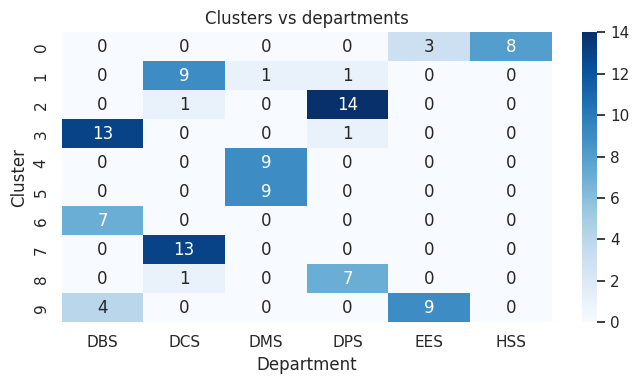

Adjusted Rand Index (clusters vs departments): 0.507   (0 = unrelated, 1 = identical)


In [42]:
ct = pd.crosstab(model_df["Cluster"], model_df["Department"])
plt.figure(figsize=(7, 4))
sns.heatmap(ct, annot=True, fmt="d", cmap="Blues")
plt.title("Clusters vs departments"); plt.tight_layout(); plt.show()

ari = adjusted_rand_score(model_df["Department"], model_df["Cluster"])
print(f"Adjusted Rand Index (clusters vs departments): {ari:.3f}   (0 = unrelated, 1 = identical)")

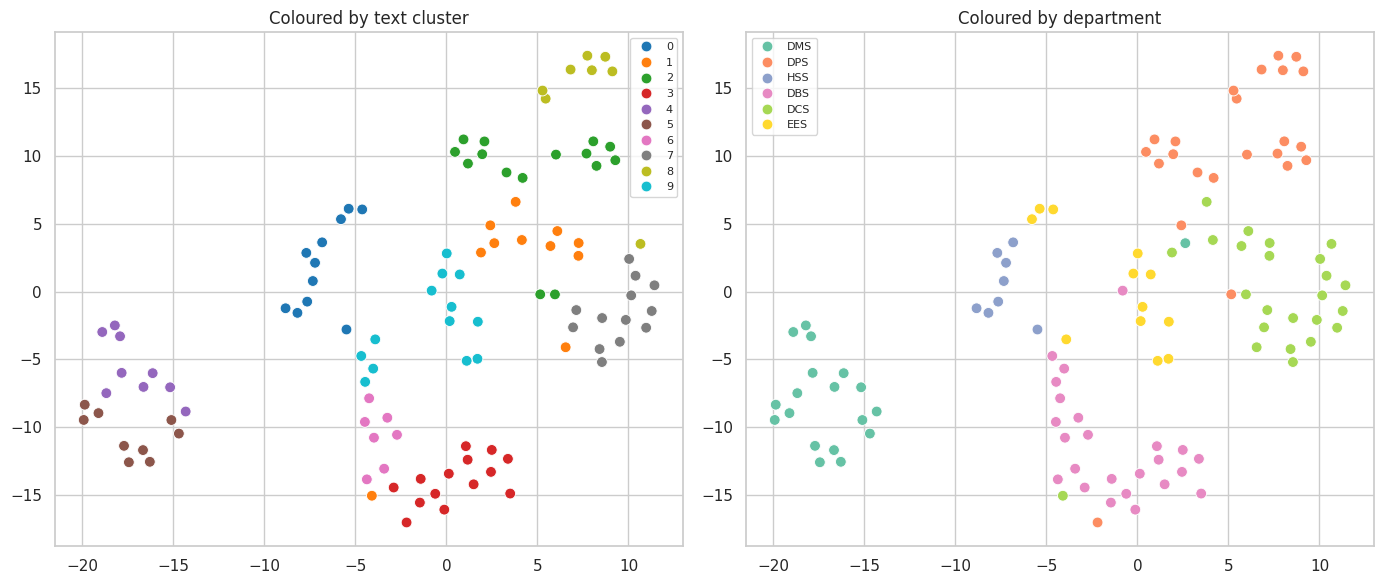

In [43]:
tsne = TSNE(n_components=2, perplexity=15, metric="cosine", init="pca", random_state=RANDOM_STATE)
P = tsne.fit_transform(Z)
model_df["tsne_x"], model_df["tsne_y"] = P[:, 0], P[:, 1]

fig, ax = plt.subplots(1, 2, figsize=(14, 6))
sns.scatterplot(data=model_df, x="tsne_x", y="tsne_y", hue="Cluster", palette="tab10", s=60, ax=ax[0])
ax[0].set_title("Coloured by text cluster")
sns.scatterplot(data=model_df, x="tsne_x", y="tsne_y", hue="Department", palette="Set2", s=60, ax=ax[1])
ax[1].set_title("Coloured by department")
for a in ax: a.set_xlabel(""); a.set_ylabel(""); a.legend(fontsize=8, loc="best")
plt.tight_layout(); plt.show()

Similarity search

In [44]:
sim = cosine_similarity(X)
name_to_idx = {n.lower(): i for i, n in enumerate(model_df["Name"])}

def find_index(name):
    name = name.lower().strip()
    if name in name_to_idx:
        return name_to_idx[name]
    hits = [i for n, i in name_to_idx.items() if name in n]
    if not hits:
        raise ValueError(f"No faculty matching '{name}'")
    return hits[0]

def similar_faculty(name, n=5):
    i = find_index(name)
    order = sim[i].argsort()[::-1]
    order = [j for j in order if j != i][:n]
    out = model_df.loc[order, ["Name", "Department", "Keywords"]].copy()
    out.insert(1, "Similarity", sim[i][order].round(3))
    print(f"Most similar to {model_df.loc[i, 'Name']} ({model_df.loc[i, 'Department']}):")
    return out

def search_by_query(query, n=5):
    q = tfidf.transform([clean_text(query)])
    s = cosine_similarity(q, X).ravel()
    order = s.argsort()[::-1][:n]
    out = model_df.loc[order, ["Name", "Department", "Keywords"]].copy()
    out.insert(1, "Score", s[order].round(3))
    print(f"Query: '{query}'")
    return out

Testing

In [45]:
demo_names = model_df.groupby("Department")["Name"].first().tolist()[:3]
for nm in demo_names:
    display(similar_faculty(nm, 5))

Most similar to Amar Deep (DBS):


,Name,Similarity,Department,Keywords
13,Arunika Mukhopadhaya,0.301,DBS,"immune, innate, responses, innate immune, bact..."
64,Rajesh Ramachandran,0.226,DBS,"molecular mechanisms, tissue, mechanisms, mole..."
27,Indranil Banerjee,0.196,DBS,"viral, entry, infection, viruses, host, pathways"
61,Rachna Chaba,0.195,DBS,"metabolism, bacterial, metabolism stress, stre..."
105,Vidya Devi Negi,0.148,DBS,"pathogen, pathogen interaction, host pathogen,..."


Most similar to Angshuman Roy Choudhury (DCS):


,Name,Similarity,Department,Keywords
59,Ramesh Ramachandran,0.258,DCS,"nmr, solid state, nmr spectroscopy, spectrosco..."
108,Yogesh Singh,0.206,DPS,"exist, phases, materials, spin, physics quantu..."
60,R. Vijaya Anand,0.155,DCS,"organic chemistry, organic, biologically, unna..."
84,Santanu Kumar Pal,0.145,DCS,"supramolecular chemistry, supramolecular, expl..."
32,Jyotima Kanaujia,0.135,EES,"seismic, wave, earth, deformation, crustal, solid"


Most similar to Abhik Ganguli (DMS):


,Name,Similarity,Department,Keywords
48,Mihir Sheth,0.618,DMS,"representation, number, langlands, langlands p..."
19,Chandrakant Sharma Aribam,0.369,DMS,"adic, galois, elliptic, extensions, questions,..."
104,Varadharaj Ravi Srinivasan,0.128,DMS,"differential, galois, solutions, linear, algeb..."
85,Santhosh Kumar Pamula,0.106,DMS,"operator, analysis, functional, operators, mat..."
99,Tanusree Khandai,0.064,DMS,"representation, lie, algebra, algebras, dimens..."


In [46]:
for q in ["protein structure and drug discovery", "quantum condensed matter", "climate and geology", "machine learning"]:
    display(search_by_query(q, 4))

Query: 'protein structure and drug discovery'


,Name,Score,Department,Keywords
90,Shashi Bhushan Pandit,0.161,DBS,"protein, proteins, bioinformatics, computation..."
75,Samarjit Bhattacharyya,0.122,DBS,"trafficking, events, protein, receptor, brain,..."
33,Kausik Chattopadhyay,0.114,DBS,"pore, membrane, pathogen interaction, host pat..."
30,Jogender Singh,0.101,DBS,"stress, metabolism, stress responses, response..."


Query: 'quantum condensed matter'


,Name,Score,Department,Keywords
83,Sanjeev Kumar,0.472,DPS,"computational methods, condensed, condensed ma..."
55,Prasenjit Das,0.395,DPS,"physics statistical, soft condensed, statistic..."
1,Abhishek Chaudhuri,0.361,DPS,"equilibrium, soft, condensed matter, condensed..."
108,Yogesh Singh,0.359,DPS,"exist, phases, materials, spin, physics quantu..."


Query: 'climate and geology'


,Name,Score,Department,Keywords
65,Raju Attada,0.518,EES,"atmospheric, climate, science, modelling, weat..."
39,Kritika M. Garg,0.218,DBS,"genomics, ancient, biodiversity, ecology, evol..."
86,Santosh B. Satbhai,0.183,DBS,"plant, plants, stress, microbe interactions, c..."
107,Vishal Bhardwaj,0.000,DPS,"energy physics, high energy, physics, energy, ..."


Query: 'machine learning'


,Name,Score,Department,Keywords
20,Chandrakanta Ojha,0.456,EES,"remote sensing, remote, sensing, groundwater, ..."
79,Sajal Kumar Giri,0.410,DCS,"machine, machine learning, learning, light mat..."
109,Yunus Ali Pulpadan,0.213,EES,"remote sensing, remote, sensing, seismic, miti..."
107,Vishal Bhardwaj,0.000,DPS,"energy physics, high energy, physics, energy, ..."


Classification

In [47]:
y = model_df["Department"].values
min_class = pd.Series(y).value_counts().min()
n_splits = int(min(5, min_class))
print("smallest class size:", min_class, "-> using", n_splits, "folds")
cv = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=RANDOM_STATE)

models = {
    "Logistic Regression": LogisticRegression(max_iter=2000, C=10, class_weight="balanced"),
    "Linear SVM":          LinearSVC(C=1, class_weight="balanced"),
}
results, preds = [], {}
for name, clf in models.items():
    pipe = make_pipeline(TfidfVectorizer(ngram_range=(1, 2), min_df=2, max_df=0.5, sublinear_tf=True), clf)
    p = cross_val_predict(pipe, model_df["Text Clean"], y, cv=cv)
    preds[name] = p
    results.append({"model": name, "accuracy": accuracy_score(y, p), "macro_F1": f1_score(y, p, average="macro")})
majority = pd.Series(y).value_counts(normalize=True).iloc[0]
results.append({"model": "Majority-class baseline", "accuracy": majority, "macro_F1": np.nan})
pd.DataFrame(results).round(3)

smallest class size: 8 -> using 5 folds


,model,accuracy,macro_F1
0,Logistic Regression,0.864,0.843
1,Linear SVM,0.873,0.859
2,Majority-class baseline,0.218,NaN


Best model: Linear SVM 

              precision    recall  f1-score   support

         DBS       0.88      0.92      0.90        24
         DCS       0.81      0.88      0.84        24
         DMS       0.95      0.95      0.95        19
         DPS       0.88      0.91      0.89        23
         EES       0.88      0.58      0.70        12
         HSS       0.88      0.88      0.88         8

    accuracy                           0.87       110
   macro avg       0.88      0.85      0.86       110
weighted avg       0.87      0.87      0.87       110



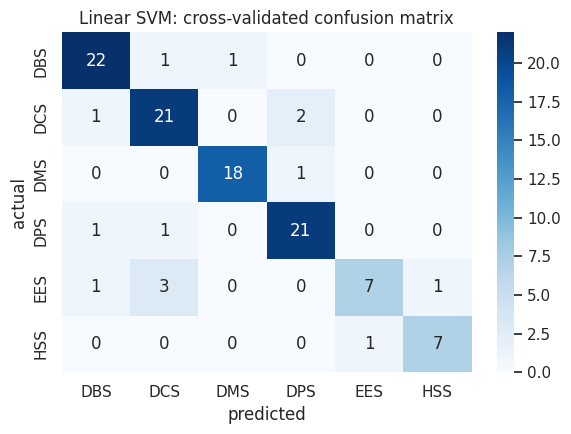

In [48]:
best = max(models, key=lambda m: f1_score(y, preds[m], average="macro"))
print("Best model:", best, "\n")
print(classification_report(y, preds[best], zero_division=0))

labels = sorted(set(y))
plt.figure(figsize=(6, 4.5))
sns.heatmap(confusion_matrix(y, preds[best], labels=labels), annot=True, fmt="d",
            xticklabels=labels, yticklabels=labels, cmap="Blues")
plt.xlabel("predicted"); plt.ylabel("actual"); plt.title(f"{best}: cross-validated confusion matrix")
plt.tight_layout(); plt.show()

Which words drive each department? (logistic regression coefficients on the full data)

In [49]:
vec = TfidfVectorizer(ngram_range=(1, 2), min_df=2, max_df=0.5, sublinear_tf=True)
Xf = vec.fit_transform(model_df["Text Clean"])
lr = LogisticRegression(max_iter=2000, C=10, class_weight="balanced").fit(Xf, y)
fn = np.array(vec.get_feature_names_out())
for i, cls in enumerate(lr.classes_):
    print(f"{cls}: ", ", ".join(fn[lr.coef_[i].argsort()[::-1][:8]]))

DBS:  biology, immunology, genetics, mechanisms, molecular, cellular, host, ecology
DCS:  chemistry, catalysis, organic, synthesis, molecules, renewable, synthetic, molecule
DMS:  algebra, geometry, algebraic, analysis, representation, operator, geometric, topology
DPS:  physics, quantum, matter, astrophysics, universe, soft, matter physics, quantum information
EES:  geochemistry, atmospheric, wastewater, crustal, remote, environmental, seismic, sources
HSS:  urban, history, labour, literary, political, science, literature, philosophy


Misclassification


In [50]:
model_df["Predicted Dept"] = preds[best]
wrong = model_df[model_df["Predicted Dept"] != model_df["Department"]]
print(f"{len(wrong)} of {len(model_df)} misclassified")
wrong[["Name", "Department", "Predicted Dept", "Keywords"]].head(15)

14 of 110 misclassified


,Name,Department,Predicted Dept,Keywords
2,Adrene Freeda Dcruz,HSS,EES,"science, addresses, charles, literary, apart, ..."
32,Jyotima Kanaujia,EES,DCS,"seismic, wave, earth, deformation, crustal, solid"
36,Kavita Dorai,DPS,DCS,"nmr, nmr spectroscopy, spectroscopy, processin..."
50,Neeraja Sahasrabudhe,DMS,DPS,"applied, probability, theoretical, models, gra..."
59,Ramesh Ramachandran,DCS,DPS,"nmr, solid state, nmr spectroscopy, spectrosco..."
65,Raju Attada,EES,HSS,"atmospheric, climate, science, modelling, weat..."
73,Sabyasachi Rakshit,DCS,DBS,"sciences, live, molecular dynamics, imaging, t..."
76,Samir Kumar Biswas,DPS,DBS,"tissue, microscopy, deep, shaping, nanophotoni..."
78,Samrat Mukhopadhyay,DBS,DCS,"biophysics, synthetic biology, chemical, cellu..."
79,Sajal Kumar Giri,DCS,DPS,"machine, machine learning, learning, light mat..."


PhD institution and country patterns

In [51]:
inst = df.loc[df["is_regular"], ["Name", "Department", "PhD Institution"]].copy()
print("PhD institution available for", inst["PhD Institution"].notna().sum(), "of", len(inst), "regular faculty")

RULES = [
    ("IISc Bangalore",    r"indian institute of science|\biisc\b"),
    ("IIT",               r"\biit\b|indian institute of technology"),
    ("IISER",             r"\biiser\b|indian institute of science education"),
    ("TIFR / IMSc / HRI / ISI / NCBS", r"tata institute|\btifr\b|mathematical sciences|\bimsc\b|harish|\bhri\b|indian statistical|\bisi\b|ncbs|national centre for biological"),
    ("Other Indian (CSIR, JNU, DU, BHU, ...)", r"\bcsir\b|jawaharlal|\bjnu\b|delhi|banaras|\bbhu\b|calcutta|pune|hyderabad|madras|mumbai|anna university|india|kanpur|bangalore|chandigarh"),
    ("USA",               r"\busa\b|united states|\bu\.s\.|new york|california|massachusetts|texas|illinois|pennsylvania|ohio|michigan|florida|princeton|harvard|stanford|\bmit\b|chicago|columbia|cornell|yale"),
    ("UK / Ireland",      r"\buk\b|united kingdom|england|cambridge|oxford|london|edinburgh|imperial|manchester|ireland"),
    ("Europe (other)",    r"germany|france|italy|spain|netherlands|switzerland|sweden|denmark|norway|finland|austria|belgium|zurich|paris|munich|berlin|heidelberg|max planck|eth"),
    ("Asia-Pacific / other", r"japan|china|korea|singapore|australia|canada|israel|taiwan|hong kong|new zealand"),
]
def bucket(s):
    if not isinstance(s, str):
        return np.nan
    for label, rx in RULES:
        if re.search(rx, s, flags=re.I):
            return label
    return "Unclassified"

inst["PhD bucket"] = inst["PhD Institution"].apply(bucket)
print(inst["PhD bucket"].value_counts(dropna=False).to_string())

PhD institution available for 96 of 122 regular faculty
PhD bucket
Other Indian (CSIR, JNU, DU, BHU, ...)    31
NaN                                       26
TIFR / IMSc / HRI / ISI / NCBS            16
IIT                                       13
Europe (other)                            12
Unclassified                               8
USA                                        5
IISc Bangalore                             5
Asia-Pacific / other                       3
IISER                                      2
UK / Ireland                               1


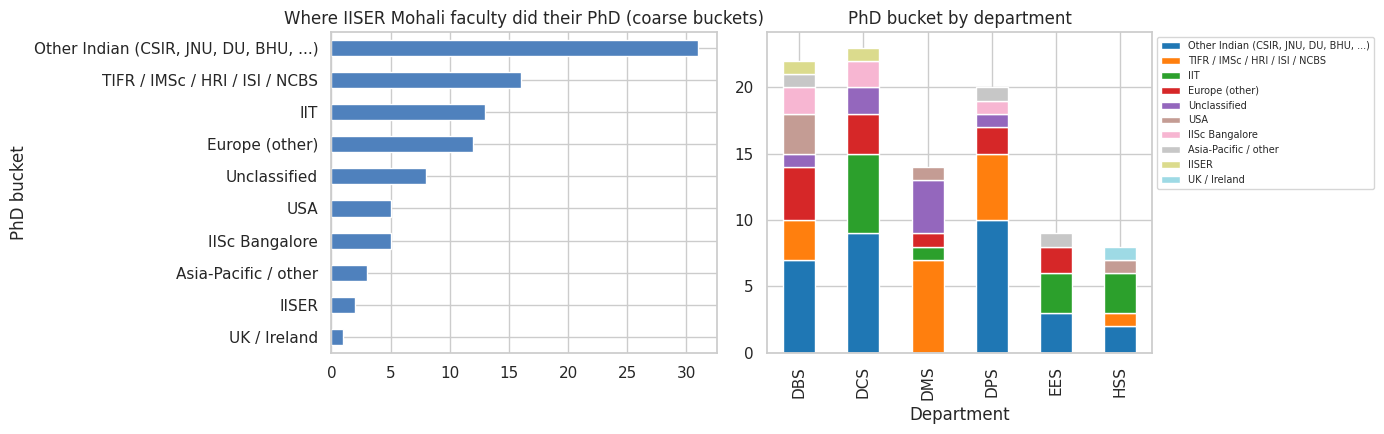

In [52]:
order = inst["PhD bucket"].value_counts().index
fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
inst["PhD bucket"].value_counts().loc[order].plot(kind="barh", ax=ax[0], color="#4f81bd").invert_yaxis()
ax[0].set_title("Where IISER Mohali faculty did their PhD (coarse buckets)")
pd.crosstab(inst["Department"], inst["PhD bucket"]).loc[:, [o for o in order]].plot(kind="bar", stacked=True, ax=ax[1], colormap="tab20")
ax[1].set_title("PhD bucket by department"); ax[1].legend(fontsize=7, bbox_to_anchor=(1, 1))
plt.tight_layout(); plt.show()

 Save outputs

In [53]:
out_cols = ["Name", "Department", "Designation", "Keywords", "Cluster", "Predicted Dept", "tsne_x", "tsne_y"]
model_df[out_cols].to_csv("faculty_clusters.csv", index=False)

conn = sqlite3.connect(DB_PATH)
model_df[out_cols].to_sql("faculty_clusters", conn, if_exists="replace", index=False)
pd.DataFrame([{"cluster": c, "top_terms": ", ".join(t)} for c, t in cluster_terms.items()]).to_sql(
    "cluster_terms", conn, if_exists="replace", index=False)
print(pd.read_sql("SELECT name FROM sqlite_master WHERE type='table'", conn))
conn.close()
print("saved faculty_clusters.csv and updated", DB_PATH)

               name
0       faculty_raw
1     faculty_clean
2  faculty_clusters
3     cluster_terms
saved faculty_clusters.csv and updated /content/iisermohali_faculty.db
